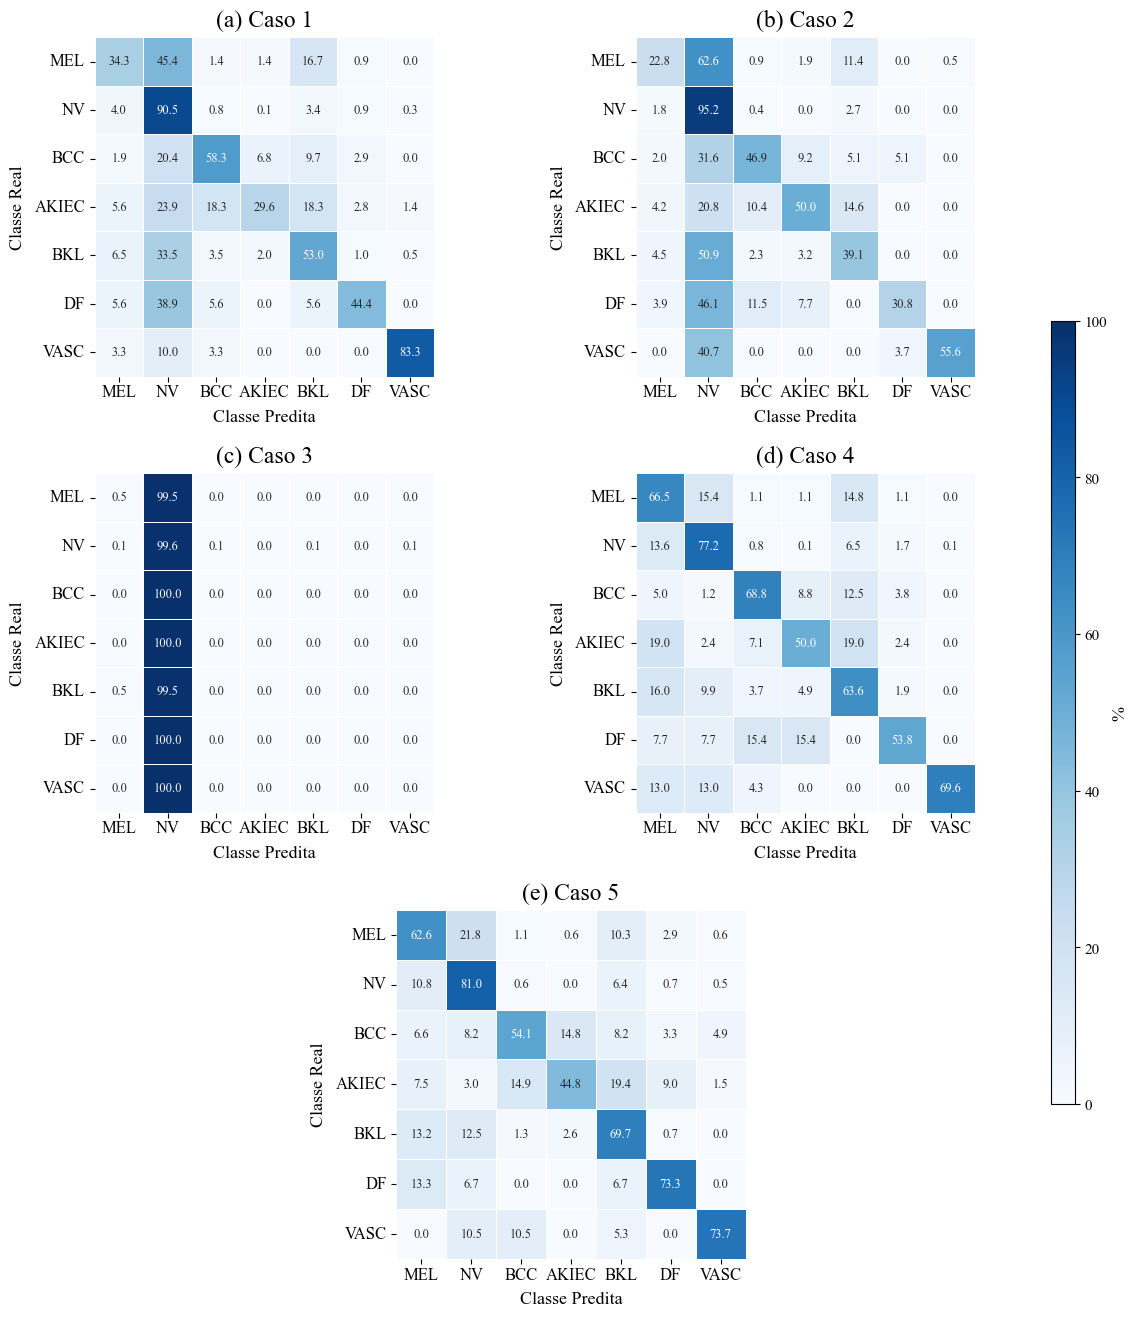

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]

# =========================
# MATRIZES
# =========================

cm1 = np.array([
    [74, 98, 3, 3, 36, 2, 0],
    [55, 1235, 11, 2, 46, 12, 4],
    [2, 21, 60, 7, 10, 3, 0],
    [4, 17, 13, 21, 13, 2, 1],
    [13, 67, 7, 4, 106, 2, 1],
    [1, 7, 1, 0, 1, 8, 0],
    [1, 3, 1, 0, 0, 0, 25]
])

cm2 = np.array([
    [22.75, 62.56, 0.95, 1.90, 11.37, 0.00, 0.47],
    [1.75, 95.19, 0.36, 0.00, 2.69, 0.00, 0.00],
    [2.04, 31.63, 46.94, 9.18, 5.10, 5.10, 0.00],
    [4.17, 20.83, 10.42, 50.00, 14.58, 0.00, 0.00],
    [4.55, 50.91, 2.27, 3.18, 39.09, 0.00, 0.00],
    [3.85, 46.15, 11.54, 7.69, 0.00, 30.77, 0.00],
    [0.00, 40.74, 0.00, 0.00, 0.00, 3.70, 55.56]
])

cm3 = np.array([
    [0.47, 99.53, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.15, 99.56, 0.07, 0.00, 0.07, 0.00, 0.15],
    [0.00, 100.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.00, 100.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.45, 99.55, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.00, 100.00, 0.00, 0.00, 0.00, 0.00, 0.00],
    [0.00, 100.00, 0.00, 0.00, 0.00, 0.00, 0.00]
])

cm4 = np.array([
    [121, 28, 2, 2, 27, 2, 0],
    [136, 773, 8, 1, 65, 17, 1],
    [4, 1, 55, 7, 10, 3, 0],
    [8, 1, 3, 21, 8, 1, 0],
    [26, 16, 6, 8, 103, 3, 0],
    [1, 1, 2, 2, 0, 7, 0],
    [3, 3, 1, 0, 0, 0, 16]
])

cm5 = np.array([
    [109, 38, 2, 1, 18, 5, 1],
    [110, 822, 6, 0, 65, 7, 5],
    [4, 5, 33, 9, 5, 2, 3],
    [5, 2, 10, 30, 13, 6, 1],
    [20, 19, 2, 4, 106, 1, 0],
    [2, 1, 0, 0, 1, 11, 0],
    [0, 2, 2, 0, 1, 0, 14]
])

matrizes = [cm1, cm2, cm3, cm4, cm5]
ja_estao_em_porcentagem = [False, True, True, False, False]
titulos = ["(a) Caso 1", "(b) Caso 2", "(c) Caso 3", "(d) Caso 4", "(e) Caso 5"]

def converter_para_porcentagem(cm):
    soma_linhas = cm.sum(axis=1, keepdims=True)
    return np.divide(
        cm,
        soma_linhas,
        out=np.zeros_like(cm, dtype=float),
        where=soma_linhas != 0
    ) * 100

matrizes_percentuais = []
for cm, ja_pct in zip(matrizes, ja_estao_em_porcentagem):
    if ja_pct:
        matrizes_percentuais.append(cm)
    else:
        matrizes_percentuais.append(converter_para_porcentagem(cm))

# =========================
# ESTILO
# =========================

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "DejaVu Serif"]

fig = plt.figure(figsize=(12, 13.5))

gs = fig.add_gridspec(
    3, 2,
    left=0.06,
    right=0.88,
    top=0.97,
    bottom=0.06,
    wspace=0.22,
    hspace=0.28,
    height_ratios=[1, 1, 1.05]
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])
ax5 = fig.add_subplot(gs[2, :])   # depois vamos centralizar

axes = [ax1, ax2, ax3, ax4, ax5]

# barra de cor única
cbar_ax = fig.add_axes([0.90, 0.18, 0.02, 0.58])

vmin, vmax = 0, 100

for ax, cm, titulo in zip(axes, matrizes_percentuais, titulos):
    sns.heatmap(
        cm,
        ax=ax,
        annot=True,
        fmt=".1f",                 # 1 casa decimal = mais legível
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        cbar=False,               # desliga barras individuais
        square=True,
        linewidths=0.4,
        linecolor="white",
        xticklabels=classes,
        yticklabels=classes,
        annot_kws={"size": 9}     # números internos maiores
    )

    ax.set_title(titulo, fontsize=17, pad=8)
    ax.set_xlabel("Classe Predita", fontsize=13, labelpad=6)
    ax.set_ylabel("Classe Real", fontsize=13, labelpad=6)

    ax.tick_params(axis="x", labelrotation=0, labelsize=12, pad=2)
    ax.tick_params(axis="y", labelrotation=0, labelsize=12)

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("center")

# centralizar o Caso 5 manualmente
pos = ax5.get_position()
new_width = 0.34
new_height = pos.height * 0.98
ax5.set_position([0.5 - new_width/2, pos.y0 + 0.005, new_width, new_height])

# criar barra de cor única
sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap="Blues")
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("%", fontsize=13)
cbar.ax.tick_params(labelsize=11)

plt.savefig("matrizes_confusao_percentual_corrigida.png", dpi=600, bbox_inches="tight")
plt.savefig("matrizes_confusao_percentual_corrigida.pdf", bbox_inches="tight")
plt.show()